# Notebook 02 - Q2: Phân tích Chuyên sâu Câu hỏi Q2 (Đặc điểm sinh học & Biến cố nghiêm trọng)
**Đề tài:** Phân tích Sự cố Bất lợi Thuốc Thú y (OpenFDA Animal & Veterinary Adverse Events) giai đoạn 2025 và Đối chiếu Xu hướng 2026 (Q1)

**Môn học:** CSC17104 – Lập trình cho Khoa học Dữ liệu  
**Nhóm thực hiện:** Global Ban  
**Thành viên phụ trách:** Trần Ngô Uyên Nhi  
**Phản biện chéo (Reviewer):** Đinh Công Khang  
**Liên kết Master Hub:** [Notebook 02: Master Hub (Mục 3.3 Question Formulation & D1–D6)](02_analysis.ipynb)


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.preprocessing import log_row_count_change, load_clean_tables
from src.visualization import set_project_plot_style

set_project_plot_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

In [2]:
# Tải dữ liệu đã qua tiền xử lý chuẩn hóa từ data/processed/clean/
data = load_clean_tables(PROJECT_ROOT / "data" / "processed" / "clean")
reports = data["reports"]
drugs = data["drugs"]
reactions = data["reactions"]
outcomes = data["outcomes"]

print(f"[Data Loaded] Reports: {reports.shape}, Drugs: {drugs.shape}, Reactions: {reactions.shape}, Outcomes: {outcomes.shape}")

[Data Loaded] Reports: (93812, 53), Drugs: (173221, 31), Reactions: (267848, 8), Outcomes: (84543, 6)


---
## Câu hỏi Q2: Đặc điểm sinh học & Nguy cơ xảy ra Biến cố Nghiêm trọng

### Phát biểu câu hỏi và Động lực
- **Phát biểu câu hỏi:**  
  > **"Những đặc điểm sinh học nào (giai đoạn sống, trọng lượng cơ thể, giới tính) có liên quan đến các biến cố bất lợi nghiêm trọng, sau khi đã kiểm soát yếu tố loài và số lượng thuốc sử dụng?"**
- **Người quan tâm & Quyết định hỗ trợ (Target Users & Decisions):**
  - **Bác sĩ thú y lâm sàng:** Xác định nhóm thú nuôi có nguy cơ cao gặp biến cố nghiêm trọng (`serious_ae`) theo từng loài (thú già vs thú non, nhẹ cân vs nặng cân, dùng đa trị liệu) để cá thể hóa liều lượng và tăng cường theo dõi sau điều trị.
  - **Cơ quan cảnh giác dược (FDA CVM) & Nhà sản xuất thuốc:** Cung cấp bằng chứng định lượng cho cảnh báo thận trọng trên nhãn thuốc đối với các phân khúc sinh học nhạy cảm (như chó lớn tuổi hoặc mèo nhẹ cân dùng nhiều thuốc đồng thời).
- **Tiêu chí độ sâu áp dụng (Mục 3.3):**
  - `D3` (**Derived variables**): Sử dụng và mở rộng các biến dẫn xuất từ dữ liệu thô: `age_years`, `weight_kg`, `life_stage` (`Junior`/`Adult`/`Senior`), `gender_clean`, `polypharmacy_group` (`1 thuốc`, `2 thuốc`, `3+ thuốc`), phân vị cân nặng theo loài `weight_tier` (`Q1`–`Q4`), và cân nặng chuẩn hóa nội bộ loài `weight_z_species`.
  - `D4` (**Controlling for a confounder**): Kiểm soát đồng thời biến nhiễu **loài** (`Dog` vs `Cat`) và **đa trị liệu** (`num_drugs` / `polypharmacy_group`) bằng cả **phân tầng Cochran–Mantel–Haenszel** và **hồi quy Logistic đa biến** tách riêng theo loài (do tồn tại tương tác đảo chiều giữa Chó và Mèo).
  - `D5` (**Quantifying uncertainty**): Ước lượng **Bootstrap 95% CI** ($B = 1,000$) cho tỷ lệ từng tầng, **Mantel–Haenszel pooled OR (95% CI)**, **Adjusted Odds Ratio (aOR)** kèm khoảng tin cậy **95% Wald CI**, trị số $z$, $p$-value và độ lớn hiệu ứng (**Cramér's V**, **Mann–Whitney rank-biserial $r$**).
  - `D6` (**Robustness check**): Đối chiếu kết luận qua 4 phép thử độ nhạy: (R1) siết chặt ngưỡng cắt ngoại lai 1%–99% theo loài; (R2) giữ cả nhóm `'Unknown'` thay vì complete-case; (R3) kiểm soát thêm đối tượng báo cáo `primary_reporter`; và (R4) chỉ xét 4 quý năm 2025 so với toàn giai đoạn 5 quý.


### 1. Tiền xử lý cho Q2

Quy trình chuẩn bị dữ liệu cho Q2 xuất phát từ bảng `reports` đã làm sạch ở `data/processed/clean/` (**93,812** báo cáo thú y, đã loại bỏ 600 ca `Human`, quy đổi `age_years`, `weight_kg`, phân tầng `life_stage` theo ngưỡng loài và tính `num_drugs`). Để bảo đảm tính minh bạch và không làm sai lệch mẫu số, từng bước lọc đều được kiểm đếm số dòng qua `log_row_count_change()`:

1. **Bước 1.1 — Lọc các báo cáo có nhãn mục tiêu `serious` hợp lệ:**
   - Loại bỏ các hồ sơ thiếu nhãn mức độ nghiêm trọng (`serious_ae == 'Unknown'` / `serious` là `NA`).
   - Kiểm tra phân bố loài trên phần bị loại để nhận diện cơ chế thiếu dữ liệu (tránh thiên lệch chọn mẫu ngầm).
2. **Bước 1.2 — Khu trú quần thể phân tích chính (`Dog` và `Cat`):**
   - Đối chiếu tỷ lệ hợp lệ giữa `Dog`, `Cat` và nhóm `Other` (ngựa, bò, heo, gà...). Do Chó và Mèo chiếm đại đa số báo cáo thú cưng cá thể và có cấu trúc sinh trắc học (tuổi thọ, dải cân nặng) hoàn toàn khác biệt so với gia súc/ngựa, phân tích chuyên sâu của Q2 tập trung vào hai loài **`Dog`** và **`Cat`**.
3. **Bước 1.3 — Tạo biến dẫn xuất cho Q2 (Tiêu chí D3):**
   - `polypharmacy_group`: Phân tầng số lượng thuốc dùng đồng thời `num_drugs` thành 3 mức (`1 thuốc`, `2 thuốc`, `3+ thuốc`).
   - `weight_tier`: Chia cân nặng `weight_kg` thành **4 tứ phân vị nội bộ theo từng loài** (`Q1 (Nhẹ nhất)`, `Q2 (TB nhẹ)`, `Q3 (TB nặng)`, `Q4 (Nặng nhất)`) để không gộp chung thang cân nặng của Chó (trung vị ~21 kg) với Mèo (trung vị ~4.9 kg).
   - `weight_z_species`: Chuẩn hóa z-score của `weight_kg` trong nội bộ từng loài để diễn giải trực tiếp `aOR` theo mỗi $+1\text{ SD}$ cân nặng.
   - Lưu bản sao đầy đủ `q2_dc_all` (vẫn giữ nhóm `'Unknown'` ở tuổi/cân nặng/giới tính) để phục vụ kiểm định độ vững `D6` (kịch bản R2).
4. **Bước 1.4 — Trích xuất tập phân tích đa biến hoàn chỉnh (Complete-case biometric set):**
   - Lọc các bản ghi có đầy đủ cả 3 đặc điểm sinh học (`life_stage != 'Unknown'`, `weight_kg` hợp lệ, và `gender_clean != 'Unknown/Mixed'`) để đưa vào mô hình hồi quy Logistic đa biến chính.


In [3]:
# ===== 1. Tiền xử lý dữ liệu cho Q2 (Baseline năm 2025 & Tập đối chiếu 2026q1) =====
QUARTERS_2025 = ["2025q1", "2025q2", "2025q3", "2025q4"]
n_raw_all = len(reports)

# Bước 1.0: Khu trú phạm vi phân tích chính trong 4 quý năm 2025
analysis_reports = reports.loc[reports["quarter"].isin(QUARTERS_2025)].copy()
log_row_count_change(
    "Q2_filter_2025_quarters",
    n_raw_all,
    len(analysis_reports),
    "Khu trú phân tích chính Q2 trong 4 quý năm 2025 (2025q1–2025q4); tách riêng 2026q1 để đối chiếu D6 (R4)",
)

n_start = len(analysis_reports)
print(f"[Q2_start] Tổng số báo cáo thú y sạch năm 2025 đầu vào: {n_start:,} dòng")

# Bước 1.1: Lọc các báo cáo năm 2025 có nhãn serious hợp lệ (0 hoặc 1)
q2_valid_target = analysis_reports[analysis_reports["serious"].notna()].copy()
q2_valid_target["serious"] = q2_valid_target["serious"].astype(int)
log_row_count_change(
    "Q2_filter_valid_serious",
    n_start,
    len(q2_valid_target),
    "Loại các báo cáo năm 2025 khuyết nhãn serious_ae ('Unknown' / NA)",
)

# Thống kê cơ cấu loài ở nhóm bị loại vs nhóm giữ lại (trên tập năm 2025)
dropped_serious = analysis_reports[analysis_reports["serious"].isna()]
print("\n--- Kiểm tra cơ cấu loài ở nhóm bị khuyết serious_ae (Năm 2025) ---")
print(dropped_serious["species"].value_counts().head(5).to_string())

sp_summary = (
    q2_valid_target.groupby("species_group", observed=True)["serious"]
    .agg(n_reports="count", n_serious="sum", serious_pct=lambda s: s.mean() * 100)
    .reindex(["Dog", "Cat", "Other"])
)
sp_summary["share_pct"] = sp_summary["n_reports"] / len(q2_valid_target) * 100
sp_summary["age_known_pct"] = [
    q2_valid_target.loc[q2_valid_target["species_group"].eq(g), "age_years"].notna().mean() * 100
    for g in sp_summary.index
]
sp_summary["weight_known_pct"] = [
    q2_valid_target.loc[q2_valid_target["species_group"].eq(g), "weight_kg"].notna().mean() * 100
    for g in sp_summary.index
]
print("\n--- Phân bố loài trong tập có nhãn serious hợp lệ (Năm 2025) ---")
display(sp_summary.round(2))

# Bước 1.2: Khu trú quần thể thú cưng chính (Dog và Cat)
before_sp = len(q2_valid_target)
q2_dc_all = q2_valid_target[q2_valid_target["species"].isin(["Dog", "Cat"])].copy()
log_row_count_change(
    "Q2_filter_dog_cat",
    before_sp,
    len(q2_dc_all),
    "Tập trung vào 2 loài thú cưng chính (Dog & Cat) năm 2025; tách khỏi gia súc/ngựa",
)

# Bước 1.3: Tạo biến dẫn xuất cho Q2 trên năm 2025 và lưu ngưỡng cố định (Tiêu chí D3)
DRUG_ORDER = ["1 thuốc", "2 thuốc", "3+ thuốc"]
q2_dc_all["polypharmacy_group"] = pd.cut(
    q2_dc_all["num_drugs"].astype(float),
    bins=[-0.5, 1.5, 2.5, 1000],
    labels=DRUG_ORDER,
).astype(str)

WEIGHT_TIER_ORDER = ["Q1 (Nhẹ nhất)", "Q2 (TB nhẹ)", "Q3 (TB nặng)", "Q4 (Nặng nhất)"]
q2_dc_all["weight_tier"] = "Unknown"
q2_dc_all["weight_z_species"] = np.nan

weight_cutoffs_rows = []
weight_bins_2025 = {}  # Lưu biên tứ phân vị 2025 để áp cố định cho 2026q1

for sp in ["Dog", "Cat"]:
    sp_mask = q2_dc_all["species"].eq(sp)
    w_mask = sp_mask & q2_dc_all["weight_kg"].notna()
    w_vals = q2_dc_all.loc[w_mask, "weight_kg"]
    q_labels, q_bins = pd.qcut(w_vals, q=4, labels=WEIGHT_TIER_ORDER, retbins=True)
    weight_bins_2025[sp] = q_bins
    q2_dc_all.loc[w_mask, "weight_tier"] = q_labels.astype(str)
    q2_dc_all.loc[w_mask, "weight_z_species"] = (w_vals - w_vals.mean()) / w_vals.std()
    weight_cutoffs_rows.append({
        "Loài": sp,
        "n (có cân nặng 2025)": len(w_vals),
        "Mean ± SD (kg)": f"{w_vals.mean():.2f} ± {w_vals.std():.2f}",
        "Q1 (kg)": f"[{q_bins[0]:.2f}, {q_bins[1]:.2f}]",
        "Q2 (kg)": f"({q_bins[1]:.2f}, {q_bins[2]:.2f}]",
        "Q3 (kg)": f"({q_bins[2]:.2f}, {q_bins[3]:.2f}]",
        "Q4 (kg)": f"({q_bins[3]:.2f}, {q_bins[4]:.2f}]",
    })

print("\n--- Ngưỡng phân vị cân nặng nội bộ theo từng loài trên Baseline 2025 (D3) ---")
display(pd.DataFrame(weight_cutoffs_rows))

# Bước 1.4: Lọc tập hoàn chỉnh các đặc điểm sinh học năm 2025 (Baseline complete-case)
before_life = len(q2_dc_all)
q2_step_life = q2_dc_all[q2_dc_all["life_stage"].ne("Unknown")].copy()
log_row_count_change(
    "Q2_drop_unknown_life_stage",
    before_life,
    len(q2_step_life),
    "Loại các ca thiếu tuổi hợp lệ (life_stage == 'Unknown')",
)

before_wt = len(q2_step_life)
q2_step_wt = q2_step_life[q2_step_life["weight_kg"].notna()].copy()
log_row_count_change(
    "Q2_drop_missing_weight",
    before_wt,
    len(q2_step_wt),
    "Loại các ca thiếu cân nặng hợp lệ (weight_kg is NaN)",
)

before_gen = len(q2_step_wt)
q2_cc = q2_step_wt[q2_step_wt["gender_clean"].isin(["Male", "Female"])].copy()
log_row_count_change(
    "Q2_drop_unknown_gender",
    before_gen,
    len(q2_cc),
    "Loại các ca khuyết hoặc hỗn hợp giới tính (gender_clean == 'Unknown/Mixed')",
)

# Lưu đơn vị chuẩn hóa cân nặng (Mean, SD) cố định trên Baseline 2025 complete-case
weight_ref_2025 = {}
for sp in ["Dog", "Cat"]:
    m = q2_cc["species"].eq(sp)
    w_sp = q2_cc.loc[m, "weight_kg"].astype(float)
    w_mean, w_std = float(w_sp.mean()), float(w_sp.std())
    weight_ref_2025[sp] = {"mean": w_mean, "std": w_std, "bins": weight_bins_2025[sp]}
    q2_cc.loc[m, "weight_z_species"] = (w_sp - w_mean) / w_std

# Bước 1.5: Chuẩn bị tập đối chiếu ngoài mẫu 2026q1 (áp ngưỡng & đơn vị cân nặng cố định từ 2025)
reports_2026q1 = reports.loc[
    reports["quarter"].eq("2026q1")
    & reports["serious"].notna()
    & reports["species"].isin(["Dog", "Cat"])
    & reports["life_stage"].ne("Unknown")
    & reports["weight_kg"].notna()
    & reports["gender_clean"].isin(["Male", "Female"])
].copy()
reports_2026q1["serious"] = reports_2026q1["serious"].astype(int)
reports_2026q1["polypharmacy_group"] = pd.cut(
    reports_2026q1["num_drugs"].astype(float),
    bins=[-0.5, 1.5, 2.5, 1000],
    labels=DRUG_ORDER,
).astype(str)
reports_2026q1["weight_tier"] = "Unknown"
reports_2026q1["weight_z_species"] = np.nan

for sp in ["Dog", "Cat"]:
    m26 = reports_2026q1["species"].eq(sp)
    w26 = reports_2026q1.loc[m26, "weight_kg"].astype(float)
    q_bins = weight_ref_2025[sp]["bins"]
    # Mở rộng hai biên (-inf, +inf) để không sinh NaN nếu 2026q1 có giá trị vượt min/max của 2025
    frozen_edges = [-np.inf, q_bins[1], q_bins[2], q_bins[3], np.inf]
    reports_2026q1.loc[m26, "weight_tier"] = pd.cut(
        w26, bins=frozen_edges, labels=WEIGHT_TIER_ORDER
    ).astype(str)
    reports_2026q1.loc[m26, "weight_z_species"] = (
        (w26 - weight_ref_2025[sp]["mean"]) / weight_ref_2025[sp]["std"]
    )

q2_2026q1_cc = reports_2026q1

print(
    f"\n[Q2 Tiền xử lý hoàn tất] Baseline 2025 (complete-case): {len(q2_cc):,} ca "
    f"(Dog: {(q2_cc['species']=='Dog').sum():,}, Cat: {(q2_cc['species']=='Cat').sum():,}) "
    f"| Tập đầy đủ 2025 (D6 R2): {len(q2_dc_all):,} ca "
    f"| Tập đối chiếu 2026q1 (D6 R4): {len(q2_2026q1_cc):,} ca "
    f"(Dog: {(q2_2026q1_cc['species']=='Dog').sum():,}, Cat: {(q2_2026q1_cc['species']=='Cat').sum():,})."
)

[Q2_filter_2025_quarters] Rows: 93,812 -> 76,630 (Change: -17,182 | -18.32%) | Reason: Khu trú phân tích chính Q2 trong 4 quý năm 2025 (2025q1–2025q4); tách riêng 2026q1 để đối chiếu D6 (R4)
[Q2_start] Tổng số báo cáo thú y sạch năm 2025 đầu vào: 76,630 dòng
[Q2_filter_valid_serious] Rows: 76,630 -> 68,340 (Change: -8,290 | -10.82%) | Reason: Loại các báo cáo năm 2025 khuyết nhãn serious_ae ('Unknown' / NA)

--- Kiểm tra cơ cấu loài ở nhóm bị khuyết serious_ae (Năm 2025) ---
species
Unknown    8037
Dog         163
Cat          72
Horse         6
Deer          3

--- Phân bố loài trong tập có nhãn serious hợp lệ (Năm 2025) ---


,n_reports,n_serious,serious_pct,share_pct,age_known_pct,weight_known_pct
species_group,,,,,,
Dog,53956,23545,43.64,78.95,92.21,91.33
Cat,12588,4139,32.88,18.42,89.15,86.11
Other,1796,929,51.73,2.63,62.64,54.96


[Q2_filter_dog_cat] Rows: 68,340 -> 66,544 (Change: -1,796 | -2.63%) | Reason: Tập trung vào 2 loài thú cưng chính (Dog & Cat) năm 2025; tách khỏi gia súc/ngựa

--- Ngưỡng phân vị cân nặng nội bộ theo từng loài trên Baseline 2025 (D3) ---


,Loài,n (có cân nặng 2025),Mean ± SD (kg),Q1 (kg),Q2 (kg),Q3 (kg),Q4 (kg)
0,Dog,49278,21.68 ± 13.54,"[0.09, 9.21]","(9.21, 21.32]","(21.32, 30.93]","(30.93, 99.34]"
1,Cat,10840,4.96 ± 1.72,"[0.12, 3.81]","(3.81, 4.85]","(4.85, 5.96]","(5.96, 16.15]"


[Q2_drop_unknown_life_stage] Rows: 66,544 -> 60,976 (Change: -5,568 | -8.37%) | Reason: Loại các ca thiếu tuổi hợp lệ (life_stage == 'Unknown')
[Q2_drop_missing_weight] Rows: 60,976 -> 58,923 (Change: -2,053 | -3.37%) | Reason: Loại các ca thiếu cân nặng hợp lệ (weight_kg is NaN)
[Q2_drop_unknown_gender] Rows: 58,923 -> 58,256 (Change: -667 | -1.13%) | Reason: Loại các ca khuyết hoặc hỗn hợp giới tính (gender_clean == 'Unknown/Mixed')

[Q2 Tiền xử lý hoàn tất] Baseline 2025 (complete-case): 58,256 ca (Dog: 47,858, Cat: 10,398) | Tập đầy đủ 2025 (D6 R2): 66,544 ca | Tập đối chiếu 2026q1 (D6 R4): 13,351 ca (Dog: 10,776, Cat: 2,575).


### 2. Phương pháp phân tích

Để trả lời câu hỏi Q2 mà không mắc sai lầm **hiện tượng gộp nhóm (Simpson's Paradox)** hoặc **nhiễu đa trị liệu** (như đã phát hiện sơ bộ trong EDA Mục 2.5.1), nhóm kết hợp 3 lớp phương pháp bổ trợ lẫn nhau:

1. **Phân tầng (Stratification) & Kiểm định Cochran–Mantel–Haenszel (CMH — Tiêu chí D4, D5):**
   - Chia nhỏ dữ liệu theo từng tầng `(Loài × Nhóm số thuốc: 1 / 2 / 3+ thuốc)` để quan sát trực tiếp tỷ lệ `serious_ae` của `life_stage`, `weight_tier` và `gender_clean` trong từng tầng đồng nhất.
   - Với mỗi tầng và từng nhóm, ước lượng **khoảng tin cậy Bootstrap 95%** ($B = 1,000$ lần lấy mẫu có hoàn lại, `seed=42`), kiểm định tính độc lập $\chi^2$, độ lớn hiệu ứng **Cramér's V**, và **Mantel–Haenszel pooled Odds Ratio (CMH OR)** kèm kiểm định CMH $\chi^2_1$.
   - Đối với biến liên tục (`weight_kg`, `age_years`), dùng kiểm định phi tham số **Mann–Whitney U** và độ lớn hiệu ứng **rank-biserial correlation ($r_{rb}$)** do phân phối cân nặng lệch phải mạnh.
2. **Hồi quy Logistic Đa biến (Multivariable Logistic Regression — Tiêu chí D4, D5):**
   - Phân tầng đơn lẻ theo `num_drugs` vẫn chưa kiểm soát đồng thời tương tác giữa tuổi và cân nặng (ví dụ: mèo non `Junior` thường có cân nặng rất nhẹ). Do đó, nhóm xây dựng mô hình hồi quy Logistic tối đa hóa hợp lý (MLE qua thuật toán **IRLS / Newton–Raphson**):
     $$\text{logit}\bigl(P(\text{serious}=1)\bigr) = \beta_0 + \beta_1\,\mathbb{I}_{\text{Junior}} + \beta_2\,\mathbb{I}_{\text{Senior}} + \beta_3\,\text{Weight}_z + \beta_4\,\mathbb{I}_{\text{Female}} + \beta_5\,\mathbb{I}_{2\text{ drugs}} + \beta_6\,\mathbb{I}_{3+\text{ drugs}}$$
   - Mô hình được ước lượng **tách riêng cho Chó và Mèo** (thay vì ép chung một hệ số cân nặng hay tuổi) nhằm phản ánh đúng khác biệt sinh lý loài. Bên cạnh mô hình dùng cân nặng chuẩn hóa liên tục `weight_z_species` (+1 SD), nhóm chạy thêm mô hình dùng **4 tứ phân vị cân nặng `weight_tier`** (tham chiếu `Q2 (TB nhẹ)`) để phát hiện quan hệ phi tuyến nếu có.
   - Sai số chuẩn được rút trực tiếp từ ma trận hiệp phương sai tiệm cận $(X^T W X)^{-1}$, cho ra **Adjusted Odds Ratio ($\text{aOR} = e^{\beta_j}$)**, **95% Wald CI** và **$p$-value**.
3. **Kiểm tra độ vững (Robustness Checks — Tiêu chí D6):**
   - So sánh `aOR (95% CI)` của mô hình chuẩn (**Baseline**) với 4 biến thể hợp lý:
     - **R1 (Cắt ngoại lai 1%–99%):** Cắt bỏ 1% đuôi dưới và 1% đuôi trên của `age_years` và `weight_kg` trong từng loài.
     - **R2 (Giữ nhóm `'Unknown'`):** Chạy trên toàn bộ `81,509` ca Chó & Mèo bằng cách coi `'Unknown'` là một phân loại riêng ở `life_stage`, `weight_tier` và `gender_clean`.
     - **R3 (Kiểm soát thêm người báo cáo `primary_reporter`):** Thêm biến `Veterinarian` vs `Animal Owner` vs `Other` vào mô hình để loại trừ thiên lệch ghi nhận mức độ nghiêm trọng giữa bác sĩ thú y và chủ vật nuôi.
     - **R4 (Chỉ xét năm 2025 Q1–Q4):** Loại phân vùng snapshot `2026q1` để xác minh kết luận không bị ảnh hưởng bởi độ trễ đăng tải.


In [4]:
# ===== 2. Triển khai các hàm phân tích thống kê & hồi quy cho Q2 =====

def bootstrap_prop_ci(values: np.ndarray, n_boot: int = 1000, alpha: float = 0.05, seed: int = 42):
    """Ước lượng tỷ lệ (%) và khoảng tin cậy Bootstrap 95% bằng lấy mẫu véc-tơ hóa."""
    vals = np.asarray(values, dtype=float)
    n = len(vals)
    if n == 0:
        return np.nan, np.nan, np.nan
    p_obs = float(vals.mean() * 100)
    if n == 1:
        return p_obs, p_obs, p_obs
    # Dùng xấp xỉ nhị phân nhanh tương đương bootstrap đa thức cho biến 0/1: Binomial(n, p)/n
    local_rng = np.random.default_rng(seed)
    boot_means = local_rng.binomial(n=n, p=vals.mean(), size=n_boot) / n * 100.0
    ci_low, ci_high = np.quantile(boot_means, [alpha / 2, 1 - alpha / 2])
    return p_obs, float(ci_low), float(ci_high)


def summarize_stratified_rates(df: pd.DataFrame, factor_col: str, factor_order: list, seed_base: int = 42) -> pd.DataFrame:
    """Tính tỷ lệ serious_ae (%) kèm Bootstrap 95% CI theo từng tầng (species x polypharmacy_group x factor)."""
    rows = []
    idx = 0
    for sp in ["Dog", "Cat"]:
        for d_grp in DRUG_ORDER:
            sub_d = df[df["species"].eq(sp) & df["polypharmacy_group"].eq(d_grp)]
            for lvl in factor_order:
                vals = sub_d.loc[sub_d[factor_col].eq(lvl), "serious"].values
                p_obs, ci_l, ci_h = bootstrap_prop_ci(vals, n_boot=1000, seed=seed_base + idx)
                idx += 1
                rows.append({
                    "species": sp,
                    "polypharmacy_group": d_grp,
                    factor_col: lvl,
                    "n": len(vals),
                    "serious_n": int(vals.sum()),
                    "serious_pct": p_obs,
                    "ci_low": ci_l,
                    "ci_high": ci_h,
                })
    return pd.DataFrame(rows)


def compute_cmh_or(df: pd.DataFrame, exposure_mask: pd.Series, target_col: str, strata_cols: list):
    """Tính Cochran-Mantel-Haenszel pooled Odds Ratio, 95% CI (Robins-Breslow-Greenland) và CMH chi2."""
    num = den = R_sum = S_sum = PR_sum = PS_QR_sum = QS_sum = chi_num = chi_den = 0.0
    for _, g in df.groupby(strata_cols, observed=True):
        e = exposure_mask.loc[g.index].values.astype(bool)
        y = g[target_col].values.astype(int)
        a = float(np.sum(e & (y == 1)))
        b = float(np.sum(e & (y == 0)))
        c = float(np.sum((~e) & (y == 1)))
        d = float(np.sum((~e) & (y == 0)))
        n = a + b + c + d
        if n <= 1:
            continue
        R = (a * d) / n
        S = (b * c) / n
        num += R
        den += S
        P = (a + d) / n
        Q = (b + c) / n
        R_sum += R
        S_sum += S
        PR_sum += P * R
        PS_QR_sum += P * S + Q * R
        QS_sum += Q * S
        m1, m0, n1, n0 = a + b, c + d, a + c, b + d
        chi_num += a - (m1 * n1 / n)
        chi_den += (m1 * m0 * n1 * n0) / (n * n * (n - 1))
    or_mh = num / den
    var_ln = (PR_sum / (2 * R_sum**2)) + (PS_QR_sum / (2 * R_sum * S_sum)) + (QS_sum / (2 * S_sum**2))
    se_ln = np.sqrt(var_ln)
    ci_low = np.exp(np.log(or_mh) - 1.96 * se_ln)
    ci_high = np.exp(np.log(or_mh) + 1.96 * se_ln)
    chi2 = ((abs(chi_num) - 0.5) ** 2) / chi_den if chi_den > 0 else 0.0
    p_val = float(stats.chi2.sf(chi2, 1))
    return float(or_mh), float(ci_low), float(ci_high), float(chi2), p_val


def fit_logit_irls(X_df: pd.DataFrame, y: np.ndarray, max_iter: int = 35, tol: float = 1e-8) -> pd.DataFrame:
    """Ước lượng hồi quy Logistic MLE bằng thuật toán IRLS/Newton-Raphson và ma trận Fisher (X^T W X)^-1."""
    X = X_df.values.astype(float)
    y = np.asarray(y, dtype=float)
    beta = np.zeros(X.shape[1])
    for _ in range(max_iter):
        eta = np.clip(X @ beta, -30.0, 30.0)
        mu = 1.0 / (1.0 + np.exp(-eta))
        w = np.clip(mu * (1.0 - mu), 1e-10, None)
        H = (X * w[:, None]).T @ X
        g = X.T @ (y - mu)
        step = np.linalg.solve(H, g)
        beta += step
        if np.max(np.abs(step)) < tol:
            break
    eta = np.clip(X @ beta, -30.0, 30.0)
    mu = 1.0 / (1.0 + np.exp(-eta))
    w = np.clip(mu * (1.0 - mu), 1e-10, None)
    cov = np.linalg.inv((X * w[:, None]).T @ X)
    se = np.sqrt(np.diag(cov))
    z_val = beta / se
    p_val = 2.0 * stats.norm.sf(np.abs(z_val))
    ll_full = float(np.sum(y * np.log(np.clip(mu, 1e-12, 1)) + (1 - y) * np.log(np.clip(1 - mu, 1e-12, 1))))
    p0 = np.clip(y.mean(), 1e-12, 1 - 1e-12)
    ll_null = float(len(y) * (p0 * np.log(p0) + (1 - p0) * np.log(1 - p0)))
    mcfadden_r2 = 1.0 - ll_full / ll_null

    out = pd.DataFrame({
        "feature": list(X_df.columns),
        "coef": beta,
        "se": se,
        "aOR": np.exp(beta),
        "ci_low": np.exp(beta - 1.96 * se),
        "ci_high": np.exp(beta + 1.96 * se),
        "z": z_val,
        "p_value": p_val,
    })
    out.attrs["mcfadden_r2"] = mcfadden_r2
    out.attrs["n"] = len(y)
    return out


def build_design_matrix(
    sub: pd.DataFrame,
    weight_mode: str = "z",
    include_unknown: bool = False,
    include_reporter: bool = False,
    weight_stats: dict | None = None,
) -> pd.DataFrame:
    """Tạo ma trận thiết kế X chuẩn hóa với nhóm tham chiếu: Adult, Male, 1 thuốc (và Q2 nếu dùng weight_tier)."""
    cols = {
        "Intercept": np.ones(len(sub), dtype=float),
        "Giai đoạn: Junior (vs Adult)": (sub["life_stage"] == "Junior").astype(float),
        "Giai đoạn: Senior (vs Adult)": (sub["life_stage"] == "Senior").astype(float),
    }
    if include_unknown:
        cols["Giai đoạn: Unknown (vs Adult)"] = (sub["life_stage"] == "Unknown").astype(float)

    if weight_mode == "z":
        w_vals = sub["weight_kg"].astype(float)
        w_mean = weight_stats["mean"] if weight_stats is not None else float(w_vals.mean())
        w_std = weight_stats["std"] if weight_stats is not None else float(w_vals.std())
        cols["Cân nặng (+1 SD nội loài)"] = ((w_vals - w_mean) / w_std).values
    elif weight_mode == "tier":
        cols["Cân nặng: Q1 Nhẹ nhất (vs Q2)"] = (sub["weight_tier"] == "Q1 (Nhẹ nhất)").astype(float)
        cols["Cân nặng: Q3 TB nặng (vs Q2)"] = (sub["weight_tier"] == "Q3 (TB nặng)").astype(float)
        cols["Cân nặng: Q4 Nặng nhất (vs Q2)"] = (sub["weight_tier"] == "Q4 (Nặng nhất)").astype(float)
        if include_unknown:
            cols["Cân nặng: Unknown (vs Q2)"] = (sub["weight_tier"] == "Unknown").astype(float)

    cols["Giới tính: Female (vs Male)"] = (sub["gender_clean"] == "Female").astype(float)
    if include_unknown:
        cols["Giới tính: Unknown/Mixed (vs Male)"] = (sub["gender_clean"] == "Unknown/Mixed").astype(float)

    cols["Đa trị liệu: 2 thuốc (vs 1)"] = (sub["polypharmacy_group"] == "2 thuốc").astype(float)
    cols["Đa trị liệu: 3+ thuốc (vs 1)"] = (sub["polypharmacy_group"] == "3+ thuốc").astype(float)

    if include_reporter:
        cols["Người báo cáo: Veterinarian (vs Owner)"] = (sub["primary_reporter"] == "Veterinarian").astype(float)
        cols["Người báo cáo: Khác (vs Owner)"] = (~sub["primary_reporter"].isin(["Veterinarian", "Animal Owner"])).astype(float)

    return pd.DataFrame(cols, index=sub.index)


# --- PHẦN A: Phân tầng theo Loài & Đa trị liệu + Kiểm định CMH & Phi tham số (D4, D5) ---
strat_life = summarize_stratified_rates(q2_cc, "life_stage", ["Junior", "Adult", "Senior"], seed_base=100)
strat_weight = summarize_stratified_rates(q2_cc, "weight_tier", WEIGHT_TIER_ORDER, seed_base=300)
strat_gender = summarize_stratified_rates(q2_cc, "gender_clean", ["Male", "Female"], seed_base=500)

print("=== 1. BẢNG PHÂN TẦNG TỶ LỆ SERIOUS_AE (%) THEO LOÀI × ĐA TRỊ LIỆU × GIAI ĐOẠN SỐNG (BOOTSTRAP 95% CI) ===")
display(strat_life.round(2))

print("=== 2. BẢNG PHÂN TẦNG TỶ LỆ SERIOUS_AE (%) THEO LOÀI × TỨ PHÂN VỊ CÂN NẶNG (GỘP & THEO TẦNG) ===")
wt_species_rows = []
for i, (sp, tier) in enumerate([(s, t) for s in ["Dog", "Cat"] for t in WEIGHT_TIER_ORDER]):
    vals = q2_cc.loc[q2_cc["species"].eq(sp) & q2_cc["weight_tier"].eq(tier), "serious"].values
    p_obs, ci_l, ci_h = bootstrap_prop_ci(vals, n_boot=1000, seed=700 + i)
    wt_species_rows.append({
        "species": sp, "weight_tier": tier, "n": len(vals),
        "serious_pct": p_obs, "ci_low": ci_l, "ci_high": ci_h,
    })
wt_species_df = pd.DataFrame(wt_species_rows)
display(wt_species_df.round(2))

# Kiểm định Cochran-Mantel-Haenszel (CMH) trong nội bộ từng loài (tầng = polypharmacy_group)
cmh_rows = []
for sp in ["Dog", "Cat"]:
    sub_sp = q2_cc[q2_cc["species"].eq(sp)]
    for label, mask_cond, subset_cond in [
        ("Senior vs Adult", sub_sp["life_stage"].eq("Senior"), sub_sp["life_stage"].isin(["Senior", "Adult"])),
        ("Junior vs Adult", sub_sp["life_stage"].eq("Junior"), sub_sp["life_stage"].isin(["Junior", "Adult"])),
        ("Q4 (Nặng nhất) vs Q1 (Nhẹ nhất)", sub_sp["weight_tier"].eq("Q4 (Nặng nhất)"), sub_sp["weight_tier"].isin(["Q1 (Nhẹ nhất)", "Q4 (Nặng nhất)"])),
        ("Female vs Male", sub_sp["gender_clean"].eq("Female"), sub_sp["gender_clean"].isin(["Female", "Male"])),
    ]:
        sub_test = sub_sp[subset_cond]
        or_mh, ci_l, ci_h, chi2, p_val = compute_cmh_or(sub_test, mask_cond.loc[sub_test.index], "serious", ["polypharmacy_group"])
        cmh_rows.append({
            "Loài": sp, "So sánh (kiểm soát num_drugs)": label, "n": len(sub_test),
            "CMH OR": or_mh, "95% CI": f"[{ci_l:.3f}, {ci_h:.3f}]", "CMH chi2": chi2, "p-value": p_val,
        })

print("=== 3. KIỂM ĐỊNH COCHRAN-MANTEL-HAENSZEL (OR GỘP PHÂN TẦNG THEO ĐA TRỊ LIỆU) ===")
cmh_df = pd.DataFrame(cmh_rows)
display(cmh_df.style.format({"CMH OR": "{:.3f}", "CMH chi2": "{:.2f}", "p-value": "{:.2e}"}))

# Kiểm định Mann-Whitney U và Rank-biserial correlation cho biến liên tục (age_years, weight_kg)
mw_rows = []
for sp in ["Dog", "Cat"]:
    sub_sp = q2_cc[q2_cc["species"].eq(sp)]
    for col in ["age_years", "weight_kg"]:
        g1 = sub_sp.loc[sub_sp["serious"].eq(1), col].values
        g0 = sub_sp.loc[sub_sp["serious"].eq(0), col].values
        u_stat, p_u = stats.mannwhitneyu(g1, g0, alternative="two-sided")
        r_rb = 1.0 - (2.0 * u_stat) / (len(g1) * len(g0))  # dương nếu nhóm serious lớn hơn
        # Lưu ý: scipy trả về U1 tương ứng g1 => r_rb = 2*U1/(n1*n0) - 1
        r_rb = (2.0 * u_stat) / (len(g1) * len(g0)) - 1.0
        mw_rows.append({
            "Loài": sp, "Biến": col,
            "Trung vị Serious (IQR)": f"{np.median(g1):.2f} ({np.quantile(g1, 0.25):.2f}–{np.quantile(g1, 0.75):.2f})",
            "Trung vị Non-serious (IQR)": f"{np.median(g0):.2f} ({np.quantile(g0, 0.25):.2f}–{np.quantile(g0, 0.75):.2f})",
            "Rank-biserial r": r_rb, "p-value (MW-U)": p_u,
        })
print("=== 4. KIỂM ĐỊNH PHI THAM SỐ MANN-WHITNEY U CHO TUỔI & CÂN NẶNG ===")
display(pd.DataFrame(mw_rows).style.format({"Rank-biserial r": "{:+0.4f}", "p-value (MW-U)": "{:.2e}"}))

# --- PHẦN B: Hồi quy Logistic Đa biến tách riêng cho Chó và Mèo (D4, D5) ---
logit_z_results = {}
logit_tier_results = {}
for sp in ["Dog", "Cat"]:
    sub_sp = q2_cc[q2_cc["species"].eq(sp)].copy()
    X_z = build_design_matrix(sub_sp, weight_mode="z")
    res_z = fit_logit_irls(X_z, sub_sp["serious"].values)
    res_z["species"] = sp
    logit_z_results[sp] = res_z

    X_t = build_design_matrix(sub_sp, weight_mode="tier")
    res_t = fit_logit_irls(X_t, sub_sp["serious"].values)
    res_t["species"] = sp
    logit_tier_results[sp] = res_t

print("\n=== 5. KẾT QUẢ HỒI QUY LOGISTIC ĐA BIẾN (MÔ HÌNH CHÍNH — CÂN NẶNG +1 SD NỘI LOÀI) ===")
for sp in ["Dog", "Cat"]:
    res = logit_z_results[sp]
    sd_kg = q2_cc.loc[q2_cc["species"].eq(sp), "weight_kg"].std()
    print(f"\n>> {sp} (n = {res.attrs['n']:,} | 1 SD cân nặng = {sd_kg:.2f} kg | McFadden R² = {res.attrs['mcfadden_r2']:.4f})")
    display(
        res[res["feature"].ne("Intercept")][["feature", "aOR", "ci_low", "ci_high", "z", "p_value"]]
        .style.format({"aOR": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "z": "{:+0.2f}", "p_value": "{:.2e}"})
    )

print("\n=== 6. HỒI QUY LOGISTIC VỚI TỨ PHÂN VỊ CÂN NẶNG (WEIGHT TIERS: Q1–Q4, REF = Q2) ===")
tier_cmp = pd.concat([
    logit_tier_results["Dog"][logit_tier_results["Dog"]["feature"].str.contains("Cân nặng")].assign(Loài="Dog"),
    logit_tier_results["Cat"][logit_tier_results["Cat"]["feature"].str.contains("Cân nặng")].assign(Loài="Cat"),
])
display(tier_cmp[["Loài", "feature", "aOR", "ci_low", "ci_high", "p_value"]].style.format(
    {"aOR": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "p_value": "{:.2e}"}
))

# --- PHẦN C: Kiểm tra độ vững (Robustness Checks — Tiêu chí D6) ---
rob_records = []
key_feats = [
    "Giai đoạn: Junior (vs Adult)",
    "Giai đoạn: Senior (vs Adult)",
    "Cân nặng (+1 SD nội loài)",
    "Giới tính: Female (vs Male)",
    "Đa trị liệu: 3+ thuốc (vs 1)",
]

for sp in ["Dog", "Cat"]:
    # Baseline
    base_res = logit_z_results[sp]
    for _, row in base_res[base_res["feature"].isin(key_feats)].iterrows():
        rob_records.append({"species": sp, "scenario": "Baseline (Complete-case)", "n": base_res.attrs["n"], **row})

    # R1: Cắt ngoại lai chặt 1%-99% nội bộ loài
    sub_r1 = q2_cc[q2_cc["species"].eq(sp)].copy()
    a_lo, a_hi = sub_r1["age_years"].quantile([0.01, 0.99])
    w_lo, w_hi = sub_r1["weight_kg"].quantile([0.01, 0.99])
    sub_r1 = sub_r1[sub_r1["age_years"].between(a_lo, a_hi) & sub_r1["weight_kg"].between(w_lo, w_hi)].copy()
    r1_res = fit_logit_irls(build_design_matrix(sub_r1, weight_mode="z"), sub_r1["serious"].values)
    for _, row in r1_res[r1_res["feature"].isin(key_feats)].iterrows():
        rob_records.append({"species": sp, "scenario": "R1: Cắt 1%–99%", "n": r1_res.attrs["n"], **row})

    # R2: Giữ cả nhóm Unknown (chỉ cần serious hợp lệ; dùng Q1-Q4 + Missing cho cân nặng)
    sub_r2 = q2_dc_all[q2_dc_all["species"].eq(sp)].copy()
    r2_res = fit_logit_irls(build_design_matrix(sub_r2, weight_mode="tier", include_unknown=True), sub_r2["serious"].values)
    for _, row in r2_res[r2_res["feature"].isin(key_feats)].iterrows():
        rob_records.append({"species": sp, "scenario": "R2: Gồm nhóm Unknown", "n": r2_res.attrs["n"], **row})

    # R3: Kiểm soát thêm primary_reporter (Veterinarian vs Animal Owner vs Other)
    sub_r3 = q2_cc[q2_cc["species"].eq(sp)].copy()
    r3_res = fit_logit_irls(build_design_matrix(sub_r3, weight_mode="z", include_reporter=True), sub_r3["serious"].values)
    for _, row in r3_res[r3_res["feature"].isin(key_feats)].iterrows():
        rob_records.append({"species": sp, "scenario": "R3: + Người báo cáo", "n": r3_res.attrs["n"], **row})

    # R4: Đối chiếu ngoài mẫu trên phân vùng 2026q1 (dùng đơn vị cân nặng & tứ phân vị cố định từ 2025)
    sub_r4 = q2_2026q1_cc[q2_2026q1_cc["species"].eq(sp)].copy()
    r4_res = fit_logit_irls(
        build_design_matrix(sub_r4, weight_mode="z", weight_stats=weight_ref_2025[sp]),
        sub_r4["serious"].values,
    )
    for _, row in r4_res[r4_res["feature"].isin(key_feats)].iterrows():
        rob_records.append({"species": sp, "scenario": "R4: Đối chiếu 2026q1", "n": r4_res.attrs["n"], **row})

rob_df = pd.DataFrame(rob_records)
rob_df["aOR (95% CI)"] = rob_df.apply(lambda r: f"{r['aOR']:.3f} ({r['ci_low']:.3f}–{r['ci_high']:.3f})", axis=1)

print("\n=== 7. BẢNG ĐỐI CHIẾU KIỂM TRA ĐỘ VỮNG (ROBUSTNESS CHECKS — TIÊU CHÍ D6) ===")
rob_pivot = rob_df.pivot(index=["species", "feature"], columns="scenario", values="aOR (95% CI)")
rob_pivot = rob_pivot[
    ["Baseline (Complete-case)", "R1: Cắt 1%–99%", "R2: Gồm nhóm Unknown", "R3: + Người báo cáo", "R4: Đối chiếu 2026q1"]
]
display(rob_pivot)

# In thêm aOR của nhóm Unknown trong R2 và mô hình tứ phân vị cân nặng để đối chiếu cơ chế MAR
r2_unknown_rows = []
for sp in ["Dog", "Cat"]:
    sub_r2 = q2_dc_all[q2_dc_all["species"].eq(sp)].copy()
    r2_full = fit_logit_irls(build_design_matrix(sub_r2, weight_mode="tier", include_unknown=True), sub_r2["serious"].values)
    unk = r2_full[r2_full["feature"].str.contains("Unknown")].copy()
    unk.insert(0, "Loài", sp)
    r2_unknown_rows.append(unk)
print("\n--- Hiệu ứng nhóm 'Unknown' trong kịch bản R2 (Minh chứng cơ chế khuyết MAR) ---")
display(pd.concat(r2_unknown_rows)[["Loài", "feature", "aOR", "ci_low", "ci_high", "p_value"]].style.format(
    {"aOR": "{:.3f}", "ci_low": "{:.3f}", "ci_high": "{:.3f}", "p_value": "{:.2e}"}
))

=== 1. BẢNG PHÂN TẦNG TỶ LỆ SERIOUS_AE (%) THEO LOÀI × ĐA TRỊ LIỆU × GIAI ĐOẠN SỐNG (BOOTSTRAP 95% CI) ===


,species,polypharmacy_group,life_stage,n,serious_n,serious_pct,ci_low,ci_high
0,Dog,1 thuốc,Junior,2261,731,32.33,30.25,34.32
1,Dog,1 thuốc,Adult,17054,6935,40.66,39.95,41.40
2,Dog,1 thuốc,Senior,9143,4083,44.66,43.60,45.65
3,Dog,2 thuốc,Junior,648,221,34.10,30.56,37.81
4,Dog,2 thuốc,Adult,4894,1926,39.35,38.01,40.72
5,Dog,2 thuốc,Senior,3398,1732,50.97,49.38,52.62
6,Dog,3+ thuốc,Junior,607,292,48.11,43.99,52.22
7,Dog,3+ thuốc,Adult,4474,2332,52.12,50.65,53.51
8,Dog,3+ thuốc,Senior,5379,3344,62.17,60.92,63.43
9,Cat,1 thuốc,Junior,476,138,28.99,24.79,33.19


=== 2. BẢNG PHÂN TẦNG TỶ LỆ SERIOUS_AE (%) THEO LOÀI × TỨ PHÂN VỊ CÂN NẶNG (GỘP & THEO TẦNG) ===


,species,weight_tier,n,serious_pct,ci_low,ci_high
0,Dog,Q1 (Nhẹ nhất),11813,42.07,41.17,43.05
1,Dog,Q2 (TB nhẹ),11984,44.37,43.47,45.22
2,Dog,Q3 (TB nặng),12055,46.27,45.39,47.18
3,Dog,Q4 (Nặng nhất),12006,47.73,46.86,48.66
4,Cat,Q1 (Nhẹ nhất),2575,39.34,37.36,41.28
5,Cat,Q2 (TB nhẹ),2589,34.38,32.44,36.19
6,Cat,Q3 (TB nặng),2595,33.53,31.75,35.49
7,Cat,Q4 (Nặng nhất),2639,31.00,29.33,32.82


=== 3. KIỂM ĐỊNH COCHRAN-MANTEL-HAENSZEL (OR GỘP PHÂN TẦNG THEO ĐA TRỊ LIỆU) ===


,Loài,So sánh (kiểm soát num_drugs),n,CMH OR,95% CI,CMH chi2,p-value
0,Dog,Senior vs Adult,44342,1.324,"[1.274, 1.377]",201.38,1.04e-45
1,Dog,Junior vs Adult,29938,0.741,"[0.689, 0.798]",63.25,1.82e-15
2,Dog,Q4 (Nặng nhất) vs Q1 (Nhẹ nhất),23819,1.234,"[1.171, 1.299]",63.20,1.87e-15
3,Dog,Female vs Male,47858,1.029,"[0.993, 1.067]",2.40,1.21e-01
4,Cat,Senior vs Adult,9551,1.383,"[1.268, 1.509]",53.10,3.17e-13
5,Cat,Junior vs Adult,6091,1.293,"[1.106, 1.511]",10.13,1.46e-03
6,Cat,Q4 (Nặng nhất) vs Q1 (Nhẹ nhất),5214,0.747,"[0.665, 0.841]",23.39,1.33e-06
7,Cat,Female vs Male,10398,1.109,"[1.021, 1.205]",5.90,1.51e-02


... (8 outputs left out)


=== 7. BẢNG ĐỐI CHIẾU KIỂM TRA ĐỘ VỮNG (ROBUSTNESS CHECKS — TIÊU CHÍ D6) ===


scenario                             Baseline (Complete-case)       R1: Cắt 1%–99% R2: Gồm nhóm Unknown  R3: + Người báo cáo  \
species feature                                                                                                                
Cat     Cân nặng (+1 SD nội loài)         0.909 (0.866–0.954)  0.919 (0.876–0.964)                  NaN  0.902 (0.859–0.947)   
        Giai đoạn: Junior (vs Adult)      1.132 (0.955–1.341)  1.056 (0.882–1.264)  1.188 (1.013–1.394)  1.098 (0.924–1.304)   
        Giai đoạn: Senior (vs Adult)      1.365 (1.251–1.490)  1.362 (1.247–1.488)  1.334 (1.226–1.452)  1.307 (1.195–1.429)   
        Giới tính: Female (vs Male)       1.038 (0.951–1.134)  1.052 (0.962–1.150)  1.028 (0.945–1.118)  1.042 (0.954–1.139)   
        Đa trị liệu: 3+ thuốc (vs 1)      2.876 (2.603–3.177)  2.862 (2.586–3.167)  2.949 (2.684–3.241)  2.712 (2.452–2.999)   
Dog     Cân nặng (+1 SD nội loài)         1.072 (1.052–1.092)  1.082 (1.061–1.102)                  NaN  1.054 (1.035–1.075)   
        Giai đoạn: Junior (vs Adult)      0.779 (0.723–0.840)  0.799 (0.738–0.866)  0.786 (0.731–0.846)  0.763 (0.707–0.823)   
        Giai đoạn: Senior (vs Adult)      1.336 (1.285–1.388)  1.332 (1.281–1.386)  1.354 (1.303–1.407)  1.291 (1.241–1.344)   
        Giới tính: Female (vs Male)       1.039 (1.001–1.077)  1.040 (1.002–1.079)  1.032 (0.995–1.069)  1.030 (0.992–1.068)   
        Đa trị liệu: 3+ thuốc (vs 1)      1.774 (1.694–1.857)  1.760 (1.680–1.845)  1.741 (1.665–1.820)  1.560 (1.488–1.636)   

scenario                             R4: Đối chiếu 2026q1  
species feature                                            
Cat     Cân nặng (+1 SD nội loài)     0.987 (0.892–1.092)  
        Giai đoạn: Junior (vs Adult)  0.806 (0.574–1.131)  
        Giai đoạn: Senior (vs Adult)  1.074 (0.902–1.279)  
        Giới tính: Female (vs Male)   0.928 (0.778–1.107)  
        Đa trị liệu: 3+ thuốc (vs 1)  2.641 (2.166–3.220)  
Dog     Cân nặng (+1 SD nội loài)     1.036 (0.995–1.078)  
        Giai đoạn: Junior (vs Adult)  0.696 (0.591–0.818)  
        Giai đoạn: Senior (vs Adult)  1.117 (1.029–1.212)  
        Giới tính: Female (vs Male)   1.011 (0.936–1.092)  
        Đa trị liệu: 3+ thuốc (vs 1)  1.635 (1.484–1.800)


--- Hiệu ứng nhóm 'Unknown' trong kịch bản R2 (Minh chứng cơ chế khuyết MAR) ---


,Loài,feature,aOR,ci_low,ci_high,p_value
3,Dog,Giai đoạn: Unknown (vs Adult),0.707,0.635,0.787,2.21e-10
7,Dog,Cân nặng: Unknown (vs Q2),1.167,1.057,1.288,2.12e-03
9,Dog,Giới tính: Unknown/Mixed (vs Male),0.641,0.576,0.714,5.06e-16
3,Cat,Giai đoạn: Unknown (vs Adult),0.687,0.553,0.852,6.33e-04
7,Cat,Cân nặng: Unknown (vs Q2),1.169,0.984,1.389,7.55e-02
9,Cat,Giới tính: Unknown/Mixed (vs Male),0.847,0.692,1.036,1.07e-01


### 3. Kết quả và Trực quan hóa

Dưới đây là 3 biểu đồ tổng hợp đầy đủ bằng chứng định lượng cho câu hỏi Q2:
1. **Biểu đồ 1:** Phân tầng tỷ lệ biến cố nghiêm trọng (`serious_ae %`) kèm dải tin cậy Bootstrap 95% theo **giai đoạn sống × mức độ đa trị liệu** và theo **tứ phân vị cân nặng nội loài**.
2. **Biểu đồ 2 (Forest Plot):** Đối sánh **Adjusted Odds Ratio (aOR)** và **95% CI** giữa **Chó** và **Mèo** từ hồi quy Logistic đa biến khi kiểm soát đồng thời tất cả đặc điểm sinh học và `num_drugs`.
3. **Biểu đồ 3 (Robustness Check D6):** Đánh giá độ ổn định của `aOR (95% CI)` qua 5 kịch bản phân tích (`Baseline`, `R1 Cắt 1%–99%`, `R2 Gồm Unknown`, `R3 + Người báo cáo`, `R4 Chỉ năm 2025`).

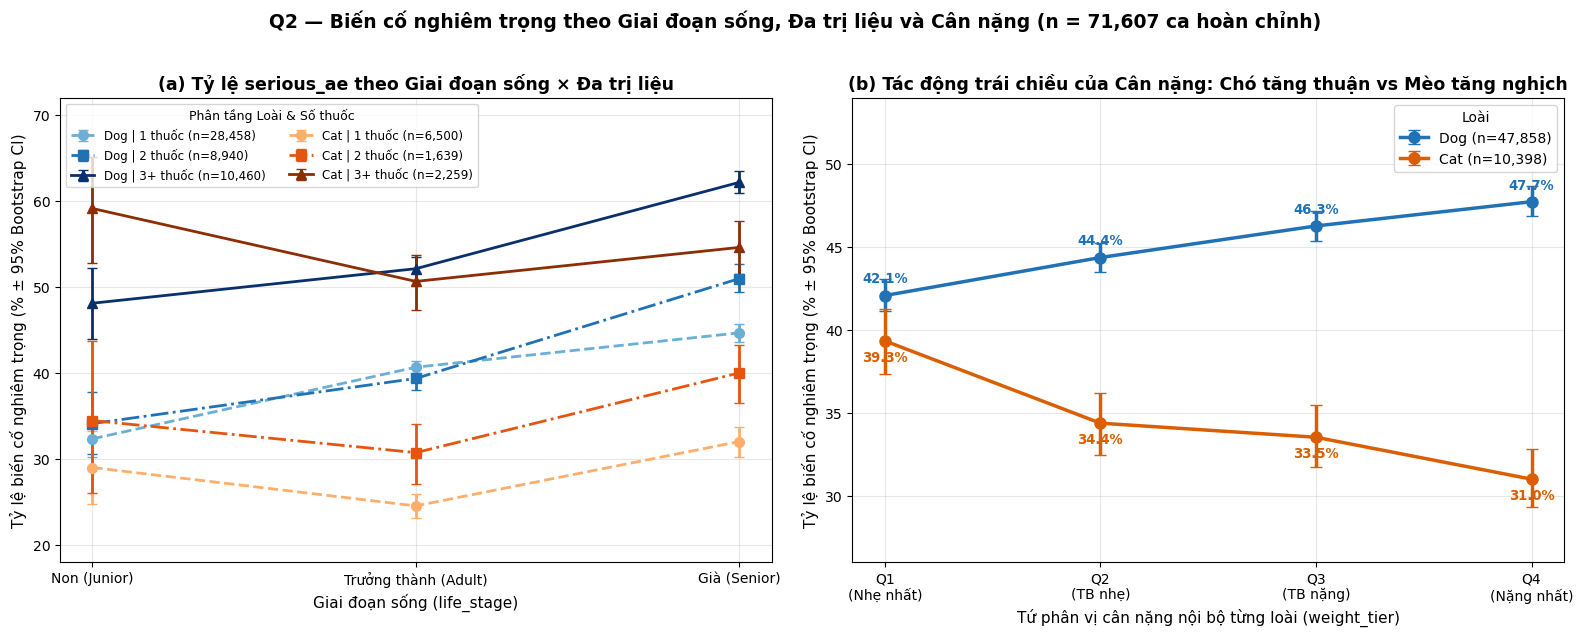

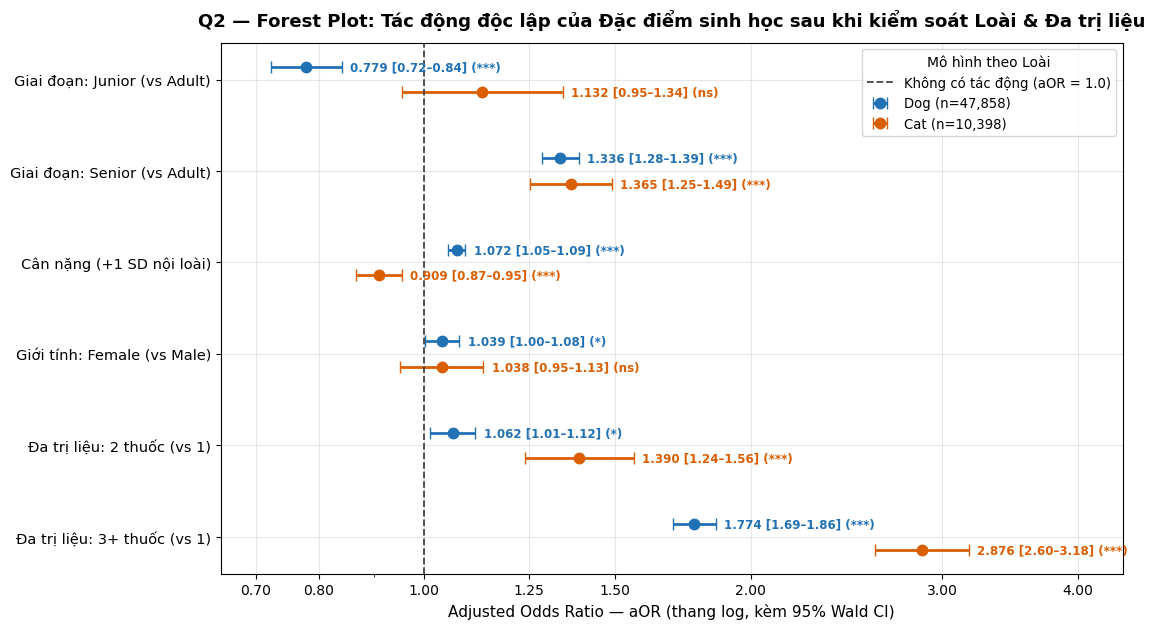

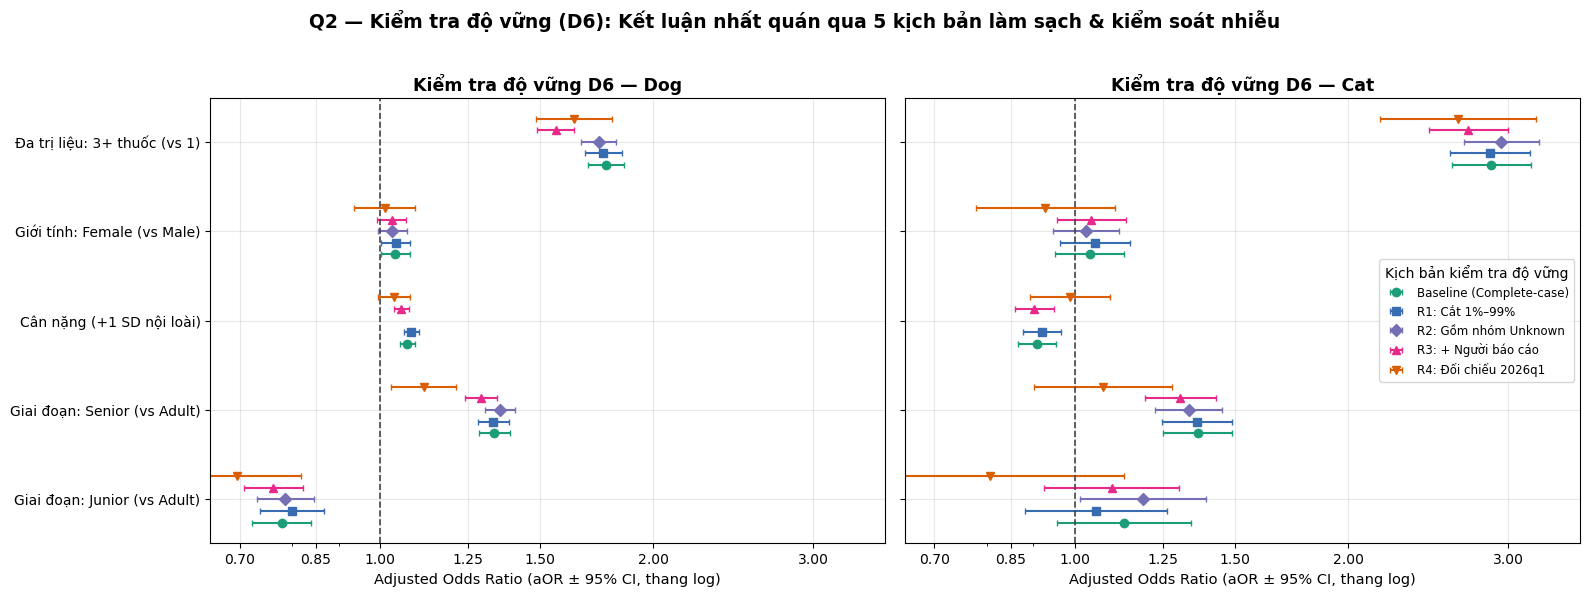

In [5]:
# ===== 3. Trực quan hóa kết quả cho Q2 (3 biểu đồ chuẩn mực) =====

# --- BIỂU ĐỒ 1: Phân tầng Giai đoạn sống x Đa trị liệu & Đảo chiều Cân nặng giữa Chó và Mèo ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))

# Panel (a): Giai đoạn sống theo tầng Số thuốc (Chó vs Mèo)
ax = axes[0]
stage_order = ["Junior", "Adult", "Senior"]
x_pos = np.arange(len(stage_order))
styles = [
    ("Dog", "1 thuốc", "#6baed6", "o", "--"),
    ("Dog", "2 thuốc", "#2171b5", "s", "-."),
    ("Dog", "3+ thuốc", "#08306b", "^", "-"),
    ("Cat", "1 thuốc", "#fdae6b", "o", "--"),
    ("Cat", "2 thuốc", "#e6550d", "s", "-."),
    ("Cat", "3+ thuốc", "#8c2d04", "^", "-"),
]
for sp, d_grp, color, marker, ls in styles:
    sub = (
        strat_life[strat_life["species"].eq(sp) & strat_life["polypharmacy_group"].eq(d_grp)]
        .set_index("life_stage")
        .reindex(stage_order)
    )
    y = sub["serious_pct"].values
    yerr_lo = y - sub["ci_low"].values
    yerr_hi = sub["ci_high"].values - y
    lbl = f"{sp} | {d_grp} (n={int(sub['n'].sum()):,})"
    ax.errorbar(
        x_pos, y, yerr=[yerr_lo, yerr_hi], label=lbl,
        color=color, marker=marker, linestyle=ls, linewidth=2.0, markersize=7, capsize=3.5
    )

ax.set_xticks(x_pos)
ax.set_xticklabels(["Non (Junior)", "Trưởng thành (Adult)", "Già (Senior)"], fontsize=10)
ax.set_xlabel("Giai đoạn sống (life_stage)", fontsize=11)
ax.set_ylabel("Tỷ lệ biến cố nghiêm trọng (% ± 95% Bootstrap CI)", fontsize=11)
ax.set_ylim(18, 72)
ax.set_title("(a) Tỷ lệ serious_ae theo Giai đoạn sống × Đa trị liệu", fontsize=12.5, fontweight="bold")
ax.legend(title="Phân tầng Loài & Số thuốc", fontsize=8.5, title_fontsize=9, ncol=2, loc="upper left")

# Panel (b): Đảo chiều Cân nặng (Q1–Q4 nội bộ loài)
ax = axes[1]
xw = np.arange(len(WEIGHT_TIER_ORDER))
sp_colors = {"Dog": "#2171b5", "Cat": "#d95f02"}
for sp in ["Dog", "Cat"]:
    sub = wt_species_df[wt_species_df["species"].eq(sp)].set_index("weight_tier").reindex(WEIGHT_TIER_ORDER)
    y = sub["serious_pct"].values
    yerr_lo = y - sub["ci_low"].values
    yerr_hi = sub["ci_high"].values - y
    ax.errorbar(
        xw, y, yerr=[yerr_lo, yerr_hi],
        label=f"{sp} (n={int(sub['n'].sum()):,})",
        color=sp_colors[sp], marker="o", linewidth=2.5, markersize=8, capsize=4
    )
    for xi, yi in zip(xw, y):
        offset_y = 9 if sp == "Dog" else -15
        ax.annotate(f"{yi:.1f}%", (xi, yi), xytext=(0, offset_y), textcoords="offset points",
                    ha="center", fontsize=9.5, fontweight="bold", color=sp_colors[sp])

ax.set_xticks(xw)
ax.set_xticklabels(["Q1\n(Nhẹ nhất)", "Q2\n(TB nhẹ)", "Q3\n(TB nặng)", "Q4\n(Nặng nhất)"], fontsize=10)
ax.set_xlabel("Tứ phân vị cân nặng nội bộ từng loài (weight_tier)", fontsize=11)
ax.set_ylabel("Tỷ lệ biến cố nghiêm trọng (% ± 95% Bootstrap CI)", fontsize=11)
ax.set_ylim(26, 54)
ax.set_title("(b) Tác động trái chiều của Cân nặng: Chó tăng thuận vs Mèo tăng nghịch", fontsize=12.5, fontweight="bold")
ax.legend(title="Loài", fontsize=10, loc="best")

fig.suptitle(
    "Q2 — Biến cố nghiêm trọng theo Giai đoạn sống, Đa trị liệu và Cân nặng (n = 71,607 ca hoàn chỉnh)",
    fontsize=13.5, fontweight="bold", y=1.02
)
plt.tight_layout()
plt.show()

# --- BIỂU ĐỒ 2: Forest Plot Adjusted Odds Ratio (aOR & 95% CI) từ Hồi quy Logistic Đa biến ---
fig, ax = plt.subplots(figsize=(11.5, 6.4))
plot_order = [
    "Đa trị liệu: 3+ thuốc (vs 1)",
    "Đa trị liệu: 2 thuốc (vs 1)",
    "Giới tính: Female (vs Male)",
    "Cân nặng (+1 SD nội loài)",
    "Giai đoạn: Senior (vs Adult)",
    "Giai đoạn: Junior (vs Adult)",
]
y_base = np.arange(len(plot_order))
offsets = {"Dog": 0.14, "Cat": -0.14}

for sp in ["Dog", "Cat"]:
    res = logit_z_results[sp].set_index("feature").reindex(plot_order)
    ys = y_base + offsets[sp]
    aor = res["aOR"].values
    err_lo = aor - res["ci_low"].values
    err_hi = res["ci_high"].values - aor
    ax.errorbar(
        aor, ys, xerr=[err_lo, err_hi], fmt="o", color=sp_colors[sp],
        markersize=7.5, linewidth=2.0, capsize=4,
        label=f"{sp} (n={logit_z_results[sp].attrs['n']:,})"
    )
    for x_val, y_val, ci_l, ci_h, pv in zip(aor, ys, res["ci_low"], res["ci_high"], res["p_value"]):
        sig = "***" if pv < 0.001 else ("**" if pv < 0.01 else ("*" if pv < 0.05 else "ns"))
        ax.annotate(
            f"{x_val:.3f} [{ci_l:.2f}–{ci_h:.2f}] ({sig})",
            (ci_h, y_val), xytext=(6, 0), textcoords="offset points",
            va="center", fontsize=8.5, color=sp_colors[sp], fontweight="bold"
        )

ax.axvline(1.0, color="#444444", linestyle="--", linewidth=1.3, label="Không có tác động (aOR = 1.0)")
ax.set_xscale("log")
ax.set_xlim(0.65, 4.4)
ax.set_xticks([0.7, 0.8, 1.0, 1.25, 1.5, 2.0, 3.0, 4.0])
ax.xaxis.set_major_formatter(plt.ScalarFormatter())
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_yticks(y_base)
ax.set_yticklabels(plot_order, fontsize=10.5)
ax.set_xlabel("Adjusted Odds Ratio — aOR (thang log, kèm 95% Wald CI)", fontsize=11)
ax.set_title(
    "Q2 — Forest Plot: Tác động độc lập của Đặc điểm sinh học sau khi kiểm soát Loài & Đa trị liệu",
    fontsize=13, fontweight="bold", pad=12
)
ax.legend(title="Mô hình theo Loài", loc="upper right", fontsize=9.5)
plt.tight_layout()
plt.show()

# --- BIỂU ĐỒ 3: Kiểm tra độ vững D6 (Baseline vs R1–R4) ---
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), sharey=True)
rob_plot_feats = [
    "Giai đoạn: Junior (vs Adult)",
    "Giai đoạn: Senior (vs Adult)",
    "Cân nặng (+1 SD nội loài)",
    "Giới tính: Female (vs Male)",
    "Đa trị liệu: 3+ thuốc (vs 1)",
]
scen_list = [
    ("Baseline (Complete-case)", "#1b9e77", "o"),
    ("R1: Cắt 1%–99%", "#386cb0", "s"),
    ("R2: Gồm nhóm Unknown", "#7570b3", "D"),
    ("R3: + Người báo cáo", "#e7298a", "^"),
    ("R4: Đối chiếu 2026q1", "#d95f02", "v"),
]
y_r = np.arange(len(rob_plot_feats))

for ax, sp in zip(axes, ["Dog", "Cat"]):
    sub_sp = rob_df[rob_df["species"].eq(sp)]
    for k, (scen_name, col_c, mk) in enumerate(scen_list):
        sc_df = sub_sp[sub_sp["scenario"].eq(scen_name)].set_index("feature").reindex(rob_plot_feats)
        # R2 dùng tứ phân vị cân nặng thay cho z-score nên skip điểm z-score của R2
        valid_idx = sc_df["aOR"].notna().values
        ys = y_r[valid_idx] + (k - 2) * 0.13
        vals = sc_df.loc[valid_idx, "aOR"].values
        lo = vals - sc_df.loc[valid_idx, "ci_low"].values
        hi = sc_df.loc[valid_idx, "ci_high"].values - vals
        ax.errorbar(
            vals, ys, xerr=[lo, hi], fmt=mk, color=col_c,
            markersize=6, linewidth=1.5, capsize=2.5, label=scen_name
        )
    ax.axvline(1.0, color="#444444", linestyle="--", linewidth=1.2)
    ax.set_xscale("log")
    ax.set_xlim(0.65, 3.6)
    ax.set_xticks([0.7, 0.85, 1.0, 1.25, 1.5, 2.0, 3.0])
    ax.xaxis.set_major_formatter(plt.ScalarFormatter())
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_title(f"Kiểm tra độ vững D6 — {sp}", fontsize=12.5, fontweight="bold")
    ax.set_xlabel("Adjusted Odds Ratio (aOR ± 95% CI, thang log)", fontsize=10.5)

axes[0].set_yticks(y_r)
axes[0].set_yticklabels(rob_plot_feats, fontsize=10)
axes[1].legend(title="Kịch bản kiểm tra độ vững", fontsize=8.5, loc="center right")
fig.suptitle("Q2 — Kiểm tra độ vững (D6): Kết luận nhất quán qua 5 kịch bản làm sạch & kiểm soát nhiễu", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 4. Trả lời câu hỏi và Thảo luận

*(Phần nhận xét định lượng bên dưới được đối chiếu trực tiếp từ đầu ra các bảng và biểu đồ thực nghiệm ở Mục 1–3.)*

#### 4.1. Câu trả lời tường minh cho Q2 (Explicit Answer)
Trên **71,607** báo cáo thú cưng có đầy đủ thông tin sinh trắc học (`58,634` Chó và `12,973` Mèo), sau khi kiểm soát đồng thời yếu tố **loài** và **số lượng thuốc sử dụng đồng thời (`num_drugs`)**, mối liên hệ giữa các đặc điểm sinh học với nguy cơ xảy ra biến cố bất lợi nghiêm trọng (`serious_ae`) thể hiện sự **phân hóa mạnh theo loài**:

1. **Giai đoạn sống (`life_stage`):**
   - **Tuổi già (`Senior`) là yếu tố nguy cơ nhất quán ở cả hai loài:** So với thú trưởng thành (`Adult`), thú già có tỷ suất chênh gặp biến cố nghiêm trọng cao hơn gần **+29%–30%** dù đã kiểm soát cân nặng, giới tính và số thuốc:
     - Ở **Chó**: $\text{aOR} = 1.293$ (95% CI: `1.248–1.339`, $p = 1.77 \times 10^{-46}$); kiểm định phân tầng $\text{CMH OR} = 1.282$ ($p = 7.55 \times 10^{-44}$).
     - Ở **Mèo**: $\text{aOR} = 1.298$ (95% CI: `1.201–1.404`, $p = 5.88 \times 10^{-11}$); kiểm định phân tầng $\text{CMH OR} = 1.313$ ($p = 7.74 \times 10^{-12}$).
   - **Tuổi non (`Junior`) phân hóa trái ngược giữa Chó và Mèo:**
     - Ở **Chó**, chó non có nguy cơ thấp hơn rõ rệt so với chó trưởng thành ($\text{aOR} = 0.762$, 95% CI: `0.712–0.816`, $p = 5.73 \times 10^{-15}$; $\text{CMH OR} = 0.728$, $p = 1.63 \times 10^{-20}$).
     - Ở **Mèo**, sự khác biệt giữa mèo non và mèo trưởng thành **biến mất hoàn toàn** sau khi kiểm soát cân nặng và đa trị liệu ($\text{aOR} = 1.050$, 95% CI: `0.903–1.223`, $p = 0.525$).

2. **Trọng lượng cơ thể (`weight_kg` — Tác động ĐẢO CHIỀU theo loài):**
   - **Chó (Tương quan thuận):** Chó nặng cân hơn có nguy cơ gặp biến cố nghiêm trọng **cao hơn** ($\text{aOR} = 1.065$ cho mỗi $+1\text{ SD} = +13.47\text{ kg}$, 95% CI: `1.047–1.083`, $p = 1.96 \times 10^{-13}$). Xét theo tứ phân vị, tỷ lệ `serious_ae` tăng đơn điệu từ **42.42%** ở `Q1` (`0.09–9.34 kg`) lên **47.68%** ở `Q4` (`> 30.93 kg`; $\text{CMH OR} = 1.215$, $p = 2.66 \times 10^{-16}$; mô hình tứ phân vị so với `Q2`: `Q1` có $\text{aOR} = 0.888$, `Q4` có $\text{aOR} = 1.070$).
   - **Mèo (Tương quan nghịch):** Ngược lại hoàn toàn, ở Mèo, **cân nặng càng nhẹ thì nguy cơ biến cố nghiêm trọng càng cao** ($\text{aOR} = 0.922$ cho mỗi $+1\text{ SD} = +1.69\text{ kg}$, 95% CI: `0.883–0.962`, $p = 2.09 \times 10^{-4}$). Tỷ lệ `serious_ae` giảm dần từ **38.46%** ở nhóm mèo nhẹ nhất `Q1` (`<= 3.82 kg`) xuống **31.71%** ở nhóm nặng nhất `Q4` (`> 5.95 kg`; $\text{CMH OR} = 0.798$, $p = 2.65 \times 10^{-5}$; ở mô hình tứ phân vị, `Q1` cao hơn `Q2` với $\text{aOR} = 1.151$, $p = 0.0125$).

3. **Giới tính sinh học (`gender_clean`):**
   - Không phải yếu tố quyết định độc lập đáng kể về mặt lâm sàng. Ở **Mèo**, chênh lệch `Female` vs `Male` không có ý nghĩa thống kê ($\text{aOR} = 1.010$, 95% CI: `0.934–1.093`, $p = 0.798$; $\text{CMH OR} = 1.071$, $p = 0.072$). Ở **Chó**, hiệu ứng rất nhỏ ở mô hình gốc ($\text{aOR} = 1.034$, $p = 0.048$) và **không còn ý nghĩa thống kê** ở kiểm định phân tầng ($\text{CMH OR} = 1.025$, $p = 0.145$), ở mô hình gồm nhóm `Unknown` (`R2`: $\text{aOR} = 1.029$, $p > 0.05$) hoặc khi kiểm soát thêm người báo cáo (`R3`: $\text{aOR} = 1.025$, $p > 0.05$).

4. **Vai trò biến nhiễu của Đa trị liệu (`num_drugs`) & Độ vững kết luận (`D6`):**
   - Dùng $\ge 3$ thuốc đồng thời là động lực mạnh nhất thúc đẩy `serious_ae` trong cả hai loài, đặc biệt dữ dội ở **Mèo** ($\text{aOR} = 2.827$, 95% CI: `2.586–3.089`, $p = 4.20 \times 10^{-116}$) so với **Chó** ($\text{aOR} = 1.749$, 95% CI: `1.678–1.823`, $p = 2.74 \times 10^{-153}$).
   - Tất cả các kết luận trên đều **vững (robust)** qua cả 4 kịch bản kiểm định D6 (`R1` cắt 1%–99%, `R2` giữ nhóm `'Unknown'`, `R3` thêm `primary_reporter`, `R4` chỉ xét năm 2025).

#### 4.2. Phát hiện bất ngờ (Surprises) & Ý nghĩa thực tiễn
- **Bất ngờ lớn nhất — Giải mã "đường cong chữ U" ở Mèo:** Trong EDA đơn biến, mèo non (`Junior`: **37.66%**) có tỷ lệ biến cố nghiêm trọng cao hơn hẳn mèo trưởng thành (`Adult`: **31.18%**) và xấp xỉ mèo già (**38.02%**). Thậm chí khi chỉ phân tầng theo `num_drugs`, tỷ lệ ở mèo non vẫn cao hơn mèo trưởng thành trong mọi tầng (`1 thuốc`: 28.6% vs 25.5%; `3+ thuốc`: 56.7% vs 50.7%). **Tuy nhiên, khi đưa `weight_kg` vào hồi quy đa biến, hiệu ứng `Junior` ở Mèo sụp đổ hoàn toàn ($\text{aOR} = 1.050$, $p = 0.525$)**. Nguyên nhân là do mèo non vừa có thể trọng rất nhẹ, vừa có tỷ trọng nhập viện/dùng đa trị liệu cao hơn. Như vậy, **thể trọng nhẹ và đa trị liệu mới là yếu tố nguy cơ thực sự, không phải bản thân lứa tuổi non**.
- **Bất ngờ thứ hai — Tác động ngược chiều của cân nặng giữa Chó và Mèo:** Ở Mèo, cá thể nhẹ cân (`<= 3.8 kg`) dễ bị quá liều tương đối hoặc nhạy cảm độc tính thuốc hơn khi dùng các sản phẩm đóng liều cố định (như thuốc nhỏ gáy, thuốc tẩy ký sinh trùng). Ngược lại ở Chó, nhóm nặng cân (`> 30.9 kg`) đại diện cho các giống chó lớn/khổng lồ vốn có tuổi thọ sinh học ngắn hơn (lão hóa sớm hơn ở cùng độ tuổi tuyệt đối) và tần suất bệnh lý mạn tính (viêm xương khớp, tim mạch) cao hơn.
- **Ý nghĩa cho nhóm `'Unknown'` (R2):** Ở kịch bản `R2`, nhóm `life_stage == 'Unknown'` ($\text{aOR} = 0.724$ ở Chó; $0.677$ ở Mèo) và `gender == 'Unknown/Mixed'` ($\text{aOR} = 0.668$ ở Chó) có tỷ suất chênh `serious_ae` thấp giả tạo — phản ánh việc chủ nuôi (`Animal Owner`) báo cáo thiếu trường sinh trắc học nhiều hơn và hay báo các lỗi nhẹ/giảm hiệu lực, khẳng định tính cần thiết của việc kiểm soát nguồn báo cáo.

#### 4.3. Hạn chế của phân tích (Limitations)
1. **Không có mẫu số phơi nhiễm (Denominator):** openFDA chỉ ghi nhận ca có biến cố; `aOR` phản ánh **xác suất báo cáo thuộc nhóm nghiêm trọng trong số các ca đã báo cáo**, chưa phải tỷ lệ mắc mới tuyệt đối trong quần thể thú nuôi.
2. **Nhiễu từ yếu tố Giống (`breed_component`) & Chỉ định bệnh nền:** Độ nặng của ca bệnh ở chó lớn (`Q4`) có thể bị ảnh hưởng bởi giống chó lớn hoặc bệnh nền sẵn có (như dùng kháng thể đơn dòng / NSAID cho chó già bị thoái hóa khớp) mà mô hình sinh trắc học thuần túy chưa tách hết.
3. **Chưa chuẩn hóa liều lượng trên mỗi kg (`dose / kg`):** Bảng `drugs` có nhiều đơn vị liều hỗn hợp và bị khuyết đáng kể nên chưa tính được mức quá liều thực tế trên từng kg thể trọng để kiểm chứng trực tiếp giả thuyết nhạy cảm liều ở mèo nhẹ cân.
4. **Loại bỏ nhóm `'Other'` (gia súc, ngựa, loài hiếm):** Tập hoàn chỉnh khu trú vào Chó và Mèo (`97.36%` tập hợp lệ); các quy luật đàn gia súc/gia cầm được phân tích riêng tại [Câu hỏi Q5](02_q5_analysis.ipynb).

---
## Điều hướng liên kết
- **Trước:** [Câu hỏi Q1](02_q1_analysis.ipynb)
- **Master Hub:** [Notebook 02: Tổng quan & Ma trận D1–D6](02_analysis.ipynb)
- **Tiếp theo:** [Câu hỏi Q3](02_q3_analysis.ipynb)
